# Next-pool recommendation for traders: data, splits and baseline

This notebook covers steps 2 to 5 of the project workflow for the idea in
[`research/idea_next_pool_recommendation.md`](../../research/idea_next_pool_recommendation.md):

1. **Data.** Two weeks of swap events from Ethereum, validated, with the tokens of every pool.
2. **Preprocessing and split.** What a "user", an "item" and a "new item" should be; chronological train / dev / test split; leakage checks.
3. **Baseline.** Task, metrics, protocol, and fixed baselines.
4. **Method fit.** Whether collaborative filtering does what the idea expects on this data.

The literature review is in [`research/literature/literature_review_pool_recommendation.md`](../../research/literature/literature_review_pool_recommendation.md)
and the conclusions are in [`research/pool_recommendation_writeup.md`](../../research/pool_recommendation_writeup.md).

Reusable code lives in `src/scripts/dex_swaps.py` and `src/scripts/pool_recsys.py`, with tests in `tests/`.

**Running time.** From scratch the downloads take about two hours through free public endpoints. With the
data in place the notebook runs in about two minutes.

In [1]:
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../scripts")
import dex_swaps as ds
import pool_recsys as pr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)

WEEK = 50_400                                    # blocks in seven days
START = 26_049_600                               # 24 September 2026
END = START + 2 * WEEK                           # exclusive; 8 October 2026
DAY = 7_200
TRAIN_END = START + 10 * DAY                     # train: first ten days
DEV_END = START + 12 * DAY                       # dev: days 11 and 12; test: days 13 and 14
DEV_ORIGINS = [START + d * DAY for d in range(4, 11)]   # rolling evaluation points inside train and dev
TEST_ORIGIN = DEV_END
HORIZON = 2 * DAY                                # a recommendation is judged on the following two days
K = 10                                           # length of a recommendation list
BASE_SHARE = 0.10                                # a token traded by more than this share of users is a base currency

# Chart style: one fixed colour per series, thin lines, quiet grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.4, "legend.frameon": False, "font.size": 9.5,
})

## 1. Data

**What the idea needs.** For many traders, which pools they traded and when, over a period long enough to
have a "before" and an "after".

**Source.** The swap events collected for the bot fingerprinting study, extended from one week to two:
every swap on Uniswap V2 and V3 style pools, with the account that signed the transaction, read from free
public Ethereum endpoints (`ds.download_window`). New for this study: the two tokens of every pool, read
from the pool contracts (`ds.load_pool_tokens`).

The window is **14 days: blocks 26,049,600 to 26,150,399, 24 September to 8 October 2026.**

In [2]:
expected = [ds.DATA_DIR / "chunks" / f"swaps_{a}_{b}.parquet" for first in (START, START + WEEK) for a, b in ds.chunk_ranges(first, WEEK)]
if not all(path.exists() for path in expected):
    ds.download_window(START, WEEK)              # resumable
    ds.download_window(START + WEEK, WEEK)

swaps = ds.load_swaps()
swaps = swaps[(swaps["block"] >= START) & (swaps["block"] < END)].reset_index(drop=True)
pool_tokens = ds.load_pool_tokens(swaps["pool"].value_counts().index.tolist())   # cached after the first run

known_pools = set(pool_tokens.dropna()["pool"])
checks = pd.Series({
    "swaps": len(swaps), "transactions": swaps["tx_hash"].nunique(), "signing accounts (users)": swaps["tx_from"].nunique(),
    "pools": swaps["pool"].nunique(),
    "first swap": swaps["timestamp"].min().strftime("%Y-%m-%d %H:%M"), "last swap": swaps["timestamp"].max().strftime("%Y-%m-%d %H:%M"),
    "share of blocks with a swap %": 100 * swaps["block"].nunique() / (END - START),
    "duplicate events": int(swaps.duplicated(["tx_hash", "log_index"]).sum()), "missing values": int(swaps.isna().sum().sum()),
    "pools whose tokens could be read": len(known_pools), "pools that did not answer": int(pool_tokens["token0"].isna().sum()),
    "share of swaps on pools with known tokens %": 100 * swaps["pool"].isin(known_pools).mean(),
    "distinct tokens": pd.concat([pool_tokens["token0"], pool_tokens["token1"]]).nunique(),
}, name="value")
display(checks.to_frame())
swaps.groupby(swaps["timestamp"].dt.floor("D")).agg(swaps=("tx_hash", "size"), transactions=("tx_hash", "nunique"), users=("tx_from", "nunique")).T

,value
swaps,2710140
transactions,1965611
signing accounts (users),211547
pools,24630
first swap,2026-09-24 20:08
last swap,2026-10-08 21:34
share of blocks with a swap %,99.066
duplicate events,0
missing values,0
pools whose tokens could be read,24620


timestamp,2026-09-24 00:00:00+00:00,2026-09-25 00:00:00+00:00,2026-09-26 00:00:00+00:00,2026-09-27 00:00:00+00:00,2026-09-28 00:00:00+00:00,2026-09-29 00:00:00+00:00,2026-09-30 00:00:00+00:00,2026-10-01 00:00:00+00:00,2026-10-02 00:00:00+00:00,2026-10-03 00:00:00+00:00,2026-10-04 00:00:00+00:00,2026-10-05 00:00:00+00:00,2026-10-06 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-08 00:00:00+00:00
swaps,30040,191526,207802,218211,225245,193637,194956,174616,206194,164351,199887,187007,163349,175691,177628
transactions,22011,135547,145152,155797,165303,146568,141847,127887,144466,114362,137745,139378,124744,131141,133663
users,6591,25345,24679,27513,28775,27944,30476,25993,26293,21689,25534,26869,26221,27070,25922


**Validation.** The two weeks are complete (99.1% of blocks have a swap, daily counts are even), with no
duplicates and no missing values. The tokens of 24,620 of the 24,630 pools could be read, covering 99.98%
of the swaps.

**What this data does not contain:** other exchange designs (Uniswap V4, Curve, Balancer), prices, and
anything about a user beyond its trades. A "user" is a signing account; one person can have many.

## 2. Descriptive statistics: users, pools, and how skewed everything is

,value
users,"211,547.000"
pools,"24,630.000"
distinct user-pool pairs,"719,752.000"
density of the user-pool matrix %,0.014
median pools per user,1.000
users with one pool %,56.224
users with at least 5 pools,"21,990.000"
pools with fewer than 5 users %,70.329
share of swaps in the 10 most used pools %,29.251
share of swaps in the 100 most used pools %,58.561


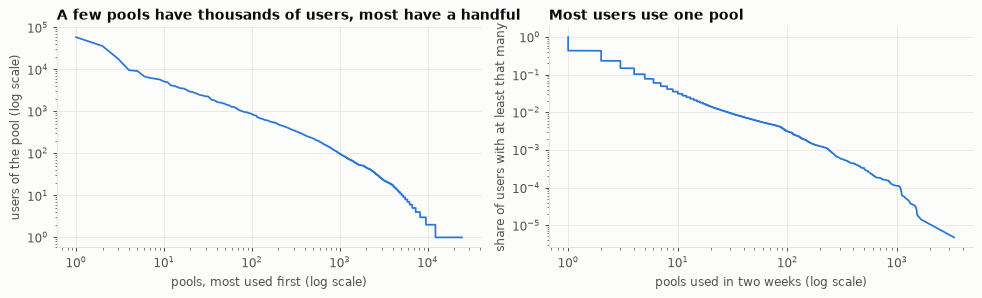

In [3]:
events = swaps.rename(columns={"tx_from": "user"})
pool_users = events.groupby("pool")["user"].nunique().sort_values(ascending=False)
user_pools = events.groupby("user")["pool"].nunique()
user_swaps = events.groupby("user").size().sort_values(ascending=False)
pool_swaps = events["pool"].value_counts()
tx_pools = swaps.groupby("tx_hash")["pool"].nunique()

stats = pd.Series({
    "users": len(user_pools), "pools": len(pool_users),
    "distinct user-pool pairs": int(events.drop_duplicates(["user", "pool"]).shape[0]),
    "density of the user-pool matrix %": 100 * events.drop_duplicates(["user", "pool"]).shape[0] / (len(user_pools) * len(pool_users)),
    "median pools per user": user_pools.median(), "users with one pool %": 100 * (user_pools == 1).mean(),
    "users with at least 5 pools": int((user_pools >= 5).sum()),
    "pools with fewer than 5 users %": 100 * (pool_users < 5).mean(),
    "share of swaps in the 10 most used pools %": 100 * pool_swaps.iloc[:10].sum() / len(swaps),
    "share of swaps in the 100 most used pools %": 100 * pool_swaps.iloc[:100].sum() / len(swaps),
    "share of swaps by the 100 most active users %": 100 * user_swaps.iloc[:100].sum() / len(swaps),
    "share of swaps by the 1,000 most active users %": 100 * user_swaps.iloc[:1000].sum() / len(swaps),
    "transactions touching more than one pool %": 100 * (tx_pools > 1).mean(),
    "swaps inside such transactions %": 100 * swaps["tx_hash"].map(tx_pools).gt(1).mean(),
}, name="value")
display(stats.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(np.arange(1, len(pool_users) + 1), pool_users.to_numpy(), color=BLUE)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("pools, most used first (log scale)"); axes[0].set_ylabel("users of the pool (log scale)")
axes[0].set_title("A few pools have thousands of users, most have a handful")
counts = np.sort(user_pools.to_numpy())
axes[1].plot(counts, 1 - np.arange(len(counts)) / len(counts), color=BLUE)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("pools used in two weeks (log scale)"); axes[1].set_ylabel("share of users with at least that many")
axes[1].set_title("Most users use one pool")
fig.tight_layout(); plt.show()

**Sizes.** There are plenty of events (2.7 million swaps) and plenty of users and pools, but the
user-pool matrix is extremely sparse and skewed in both directions:

- **Users:** 56% used a single pool in two weeks. About one in ten used five or more.
- **Pools:** 70% have fewer than five users, while the ten most used carry 29% of all swaps.
- **Activity:** the 100 most active accounts, almost certainly bots, make 27% of all swaps.

For a recommender this means that the number of *users with enough history to personalize for* is in the
thousands, not hundreds of thousands, and that popularity will be a strong reference.

## 3. Exploratory analysis and preprocessing

### 3.1 A pool is not what a trader chooses

About one transaction in five passes through more than one pool, and those transactions contain about 40%
of all swaps. A user who swaps ETH for some token through a router may be sent through ETH/USDC and then
USDC/TOKEN. The user chose the token; the router chose the pools. With pools as items, the recommender
would be asked to predict routing decisions.

`pr.trade_legs` therefore reduces each transaction to the tokens the sender ended up **selling and
buying**, dropping tokens that were only passed through.

In [4]:
legs = pr.trade_legs(swaps, pool_tokens)
train_legs = legs[legs["block"] < TRAIN_END]
token_share = train_legs.groupby("token")["user"].nunique().sort_values(ascending=False) / train_legs["user"].nunique()
BASE_TOKENS = list(token_share[token_share > BASE_SHARE].index)       # decided on the train period only
legs = legs[~legs["token"].isin(BASE_TOKENS)].reset_index(drop=True)

token_users = legs.groupby("token")["user"].nunique().sort_values(ascending=False)
user_tokens = legs.groupby("user")["token"].nunique()
print("Base currencies (share of train-period users who traded them):", {t[:10] + "…": round(s, 2) for t, s in token_share.head(len(BASE_TOKENS)).items()})
pd.Series({
    "transactions reduced to at least one bought or sold token %": 100 * pr.trade_legs(swaps, pool_tokens)["tx_hash"].nunique() / swaps["tx_hash"].nunique(),
    "users with at least one non-base token": len(user_tokens), "non-base tokens": len(token_users),
    "median tokens per user": user_tokens.median(), "users with at least 2 tokens": int((user_tokens >= 2).sum()),
    "users with at least 5 tokens": int((user_tokens >= 5).sum()),
    "tokens with at least 5 users": int((token_users >= 5).sum()), "tokens with at least 100 users": int((token_users >= 100).sum()),
    "share of buys among the legs %": 100 * (legs["side"] == "buy").mean(),
}, name="value").to_frame()

Base currencies (share of train-period users who traded them): {'0xc02aaa39…': 0.81, '0xa0b86991…': 0.4, '0xdac17f95…': 0.29}


,value
transactions reduced to at least one bought or sold token %,97.674
users with at least one non-base token,"157,060.000"
non-base tokens,"19,631.000"
median tokens per user,1.000
users with at least 2 tokens,"47,280.000"
users with at least 5 tokens,"11,000.000"
tokens with at least 5 users,"4,655.000"
tokens with at least 100 users,606.000
share of buys among the legs %,51.909


In [5]:
# How much of what looks "new" at pool level is really a new choice by the user?
def period(frame, first, last):
    return frame[(frame["block"] >= first) & (frame["block"] < last)]

pool_task = pr.build_task(pr.interactions(period(events, START, TRAIN_END), "user", "pool"),
                          pr.interactions(period(events, TRAIN_END, DEV_END), "user", "pool"))
new_pairs = pool_task["new"].tocoo()
new_pairs = pd.DataFrame({"user": pool_task["users"][new_pairs.row], "pool": pool_task["items"][new_pairs.col]}).merge(pool_tokens, on="pool", how="left")
token_history = period(legs, START, TRAIN_END).groupby("user")["token"].agg(set)
base = set(BASE_TOKENS)

def what_is_new(row):
    tokens = [t for t in (row.token0, row.token1) if t is not None and t not in base]
    if not tokens:
        return "a pool of two base currencies"
    return "a token the user already traded" if all(t in token_history.get(row.user, ()) for t in tokens) else "a token new to the user"

kinds = pd.Series([what_is_new(row) for row in new_pairs.itertuples()]).value_counts(normalize=True)
print(f"{len(new_pairs):,} user-pool pairs on dev that count as 'new' at pool level; what the pool actually is:")
(100 * kinds).round(1).to_frame("% of new pairs")

36,193 user-pool pairs on dev that count as 'new' at pool level; what the pool actually is:


,% of new pairs
a token new to the user,72.800
a pool of two base currencies,15.500
a token the user already traded,11.700


**More than a quarter of the "new pools" are not new choices.** They are pools of two base currencies
(another route or fee tier for ETH against a stablecoin) or another pool for a token the user had traded
before. A pool-level recommender would be rewarded for predicting these.

**Decision: the item is the token, not the pool.** Three tokens are traded by more than 10% of users (wrapped
ETH and the two large dollar stablecoins). They are the currencies trades are paid in, not something to
recommend, and are removed. The idea's title says "next-pool"; what can sensibly be recommended is the next
*token*. Pool-level results are still reported in section 5 for comparison.

### 3.2 Other preprocessing decisions

| Issue found in the data | Decision |
| --- | --- |
| Routed trades pass through pools the user did not choose | Items are tokens bought or sold per transaction, with pass-through tokens dropped. |
| Base currencies are in almost every trade | Tokens traded by more than 10% of train-period users are removed. The threshold is applied to the train period only. |
| Arbitrage cycles end where they start | They leave no bought or sold token and drop out, which removes much pure bot activity without a bot filter. |
| A few accounts make a large share of all swaps | Interactions are binary (used or not), and every metric is an average over users, so an account with 10,000 swaps counts as much as one with 2. |
| Half of what users do next is a repeat | "New items" and "all items" are evaluated as separate tasks. |
| Tokens that did not exist in the history | Cannot be recommended by any model here. They are counted as misses, not removed, so that the scores reflect the real task. |
| No explicit ratings, no negative feedback | Implicit feedback: a trade is a positive signal, absence of a trade is unknown. |
| Buying and selling are different acts | Both count as an interaction in the history. Section 5 checks the task with buys only as the target. |

In [6]:
def make_task(origin, frame=None, item="token", future_side=None):
    # Everything before `origin` is history; the following two days are the target.
    frame = legs if frame is None else frame
    future = period(frame, origin, origin + HORIZON)
    if future_side:
        future = future[future["side"] == future_side]
    history = pr.interactions(period(frame, START, origin), "user", item)
    task = pr.build_task(history, pr.interactions(future, "user", item))
    recent = pr.to_matrix(pr.interactions(period(frame, origin - DAY, origin), "user", item), task["users"], task["items"])
    return {"task": task, "history": history, "recent": recent}

ORIGINS = DEV_ORIGINS + [TEST_ORIGIN]
day_of = lambda origin: (origin - START) // DAY
setups = {origin: make_task(origin) for origin in ORIGINS}

rows = {}
for origin in ORIGINS:
    task = setups[origin]["task"]
    users = task["eval_users"]
    new_warm, cold = int(task["new"][users].sum()), int(task["cold_new"][users].sum())
    rows[f"after day {day_of(origin)}"] = {
        "use": "test" if origin == TEST_ORIGIN else "development",
        "history ends": period(swaps, START, origin)["timestamp"].max().strftime("%m-%d %H:%M"),
        "users in history": len(task["users"]), "tokens in history": len(task["items"]),
        "users evaluated": len(users), "new pairs to predict": new_warm + cold,
        "of which tokens absent from the history %": 100 * cold / (new_warm + cold),
        "repeat pairs of these users": int(task["repeat"][users].sum()),
    }
origin_table = pd.DataFrame(rows).T

# Save the interactions with their period (data/ is ignored by git).
legs.assign(split=np.select([legs["block"] < TRAIN_END, legs["block"] < DEV_END], ["train", "dev"], "test")).to_parquet(ds.DATA_DIR / "token_legs_with_split.parquet")
origin_table

,use,history ends,users in history,tokens in history,users evaluated,new pairs to predict,of which tokens absent from the history %,repeat pairs of these users
after day 4,development,09-28 20:39,60994,9933,8037,27349,14.922,20940
after day 5,development,09-29 20:45,72173,10699,7351,26438,21.931,20935
after day 6,development,09-30 20:51,84534,11723,7073,26223,21.557,21767
after day 7,development,10-01 20:56,93907,12572,6684,25972,20.303,22624
after day 8,development,10-02 21:02,103268,13240,7237,23573,20.065,20704
after day 9,development,10-03 21:07,110649,14701,8131,25650,24.807,21894
after day 10,development,10-04 21:11,119785,17530,8403,24583,24.008,21353
after day 12,test,10-06 21:22,138501,18701,8604,23138,21.722,23186


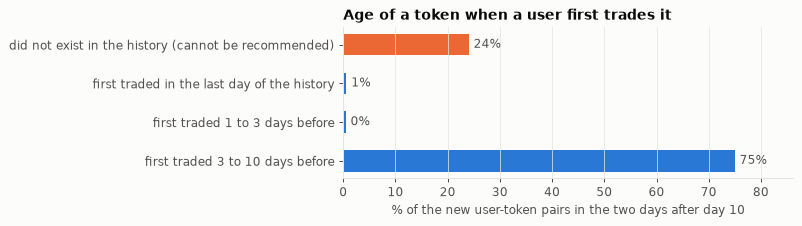

{'did not exist in the history (cannot be recommended)': 24.0, 'first traded in the last day of the history': 0.6, 'first traded 1 to 3 days before': 0.4, 'first traded 3 to 10 days before': 75.0}
24,583 new pairs; the 10 most picked tokens account for 14% of them, the 100 most picked for 39%


In [7]:
# How old is a token when a user picks it up for the first time? (last development origin)
last = setups[DEV_ORIGINS[-1]]
task, history = last["task"], last["history"]
first_seen = history.groupby("item")["first_block"].min()
new = task["new"][task["eval_users"]].tocoo()
age_days = (DEV_ORIGINS[-1] - first_seen.reindex(task["items"][new.col]).to_numpy()) / DAY
buckets = pd.Series({
    "did not exist in the history (cannot be recommended)": int(task["cold_new"][task["eval_users"]].sum()),
    "first traded in the last day of the history": int((age_days <= 1).sum()),
    "first traded 1 to 3 days before": int(((age_days > 1) & (age_days <= 3)).sum()),
    "first traded 3 to 10 days before": int((age_days > 3).sum()),
})
share = 100 * buckets / buckets.sum()

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(np.arange(len(share)), share.to_numpy(), color=[ORANGE, BLUE, BLUE, BLUE], height=0.55)
ax.set_yticks(np.arange(len(share))); ax.set_yticklabels(share.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
for y, value in enumerate(share):
    ax.annotate(f"{value:.0f}%", (value, y), xytext=(4, 0), textcoords="offset points", va="center", color=MUTED)
ax.set_xlim(0, share.max() * 1.15)
ax.set_xlabel("% of the new user-token pairs in the two days after day 10"); ax.set_title("Age of a token when a user first trades it")
fig.tight_layout(); plt.show()
top = pd.Series(task["items"][new.col]).value_counts()
print(share.round(1).to_dict())
print(f"{buckets.sum():,} new pairs; the 10 most picked tokens account for {100 * top.iloc[:10].sum() / buckets.sum():.0f}% of them, the 100 most picked for {100 * top.iloc[:100].sum() / buckets.sum():.0f}%")

### 3.3 The split

**By time, on one global timeline.** Train is the first ten days, dev days 11 and 12, test days 13 and 14.
A recommendation made at some point in time is judged on the two days that follow.

A recommender has no long training phase to protect, so the 12 development days are used more fully than
with a single cut: **seven rolling evaluation points**, after day 4, 5, ... 10. At each, everything earlier
is the history and the next two days are the target. The last target ends with day 12, so none of this
touches the test days. The **test evaluation** is the single point after day 12.

- A user is evaluated if it has a history and trades at least one token in the target that it had not
  traded before: 6,700 to 8,600 users per evaluation point.
- The targets of neighbouring points overlap by one day, so the seven development evaluations are not
  independent.

**What the split reveals about the task.**

- **15 to 25% of the tokens users pick up next did not exist in the history.** They were launched inside
  the two target days. No model built on past interactions can recommend them.
- **Almost all of the rest are established tokens.** In the chart above, three quarters of the new pairs go
  to tokens that had been trading for at least three days, and only about 1% to tokens that first appeared
  in the last three days of the history. Interest in a newly launched token seems to be concentrated in its
  first day or two: it is picked up at launch or it is an established token, with little in between.
- **The adoptions are spread widely.** The ten most picked tokens account for 14% of the new pairs and the
  hundred most picked for 39%, so a short list of favourites cannot cover them.

### 3.4 Leakage checklist

| Risk | How it is handled |
| --- | --- |
| A random or per-user "leave one out" split lets a model see other users' future | Every evaluation has one global point in time for all users (the recommendation of Ji et al., 2020). |
| Users or items of the future enter the model | Users and items are indexed from the history only (`pr.build_task`, tested). Future-only tokens count as misses. |
| Popularity or other item statistics computed on all data | Computed from the history only, including "recent" popularity. |
| The base-currency list uses the future | Decided on the first ten days only. The three tokens are the same for any cut. |
| Recommending what the user already has | In the "new items" task the user's history is removed from the ranking. |
| Sampled negatives distort the comparison | Every model ranks all tokens of the history (Krichene and Rendle, 2020). |
| Tuning on test | Candidate models and blend weights are scored at the development points only. |
| Pool tokens were read today, not at the time of the swaps | A pool's two tokens never change, so this is not a leak. |
| One person, several accounts | Not handled. It makes users look less active than they are and cannot leak labels. |

## 4. Baseline

### 4.1 Task, metrics and protocol

**Task (primary).** For each user, rank the tokens it has not traded so far. A hit is a token it trades for
the first time in the following two days.

**Task (secondary).** Rank all tokens, repeats included. A hit is any token the user trades in the following
two days.

**Metrics.**

| Metric | Definition | Why |
| --- | --- | --- |
| **Recall@10** (main) | share of the user's actual tokens that are in its list of 10, averaged over users | A user can only act on a short list. Averaging over users keeps a few very active accounts from dominating. |
| **NDCG@10** | like recall, with more credit for hits near the top | Position matters in a list. |
| **Hit rate** | share of users with at least one hit | The plainest reading: "for how many users was the list any use". |
| **Coverage** | share of all tokens that appear in anyone's list | Detects a model that recommends the same few tokens to everyone. |
| **Spread over evaluation points** | mean, lowest and highest value over the seven development points | The main source of uncertainty turns out to be the period, not the sample of users. |

**Protocol.** At each evaluation point: fit on the history, rank all tokens of the history for every
evaluated user, score against the next two days. No sampling of negatives. Development points first, then
the test point once.

**Baselines.** None of them is personalized.

| Model | What it recommends |
| --- | --- |
| **Popularity (the fixed baseline)** | The tokens with the most users in the whole history. No setting at all. |
| Recent popularity | The tokens with the most users in the last day of the history. |
| Own history (secondary task only) | The tokens the user traded before, most traded first. |

In [8]:
def recall_and_more(model, task, target="new"):
    result = pr.evaluate(model, task, K, target)
    return result, {"recall@10": result["recall"].mean(), "NDCG@10": result["ndcg"].mean(), "hit rate": result["hit"].mean(),
                    "coverage %": 100 * pr.coverage(result.attrs["recommended"], len(task["items"]))}

def summarize(per_origin):
    # per_origin: {origin: metrics dict}; mean, range over development points, and the test point.
    dev = pd.DataFrame({o: m for o, m in per_origin.items() if o != TEST_ORIGIN}).T
    row = {("development (7 points)", "recall@10"): dev["recall@10"].mean(),
           ("development (7 points)", "lowest"): dev["recall@10"].min(), ("development (7 points)", "highest"): dev["recall@10"].max(),
           ("development (7 points)", "NDCG@10"): dev["NDCG@10"].mean(), ("development (7 points)", "hit rate"): dev["hit rate"].mean(),
           ("development (7 points)", "coverage %"): dev["coverage %"].mean()}
    if TEST_ORIGIN in per_origin:
        for key in ["recall@10", "NDCG@10", "hit rate"]:
            row[("test (after day 12)", key)] = per_origin[TEST_ORIGIN][key]
    return row

fitted = {}                                       # models reused in section 5
baseline_metrics = {"Popularity (fixed baseline)": {}, "Recent popularity": {}, "all tokens: Own history": {}, "all tokens: Popularity": {}}
for origin in ORIGINS:
    setup = setups[origin]
    task = setup["task"]
    popularity, recent = pr.Popularity().fit(task["history"]), pr.Popularity().fit(setup["recent"])
    fitted[origin] = {"Popularity (fixed baseline)": popularity, "Recent popularity": recent}
    _, baseline_metrics["Popularity (fixed baseline)"][origin] = recall_and_more(popularity, task)
    _, baseline_metrics["Recent popularity"][origin] = recall_and_more(recent, task)
    counts_task = {**task, "history": pr.to_matrix(setup["history"], task["users"], task["items"], binary=False)}
    _, baseline_metrics["all tokens: Own history"][origin] = recall_and_more(pr.OwnHistory().fit(counts_task["history"]), counts_task, "all")
    _, baseline_metrics["all tokens: Popularity"][origin] = recall_and_more(popularity, task, "all")

baseline_table = pd.DataFrame({name: summarize(values) for name, values in baseline_metrics.items()}).T
baseline_table.columns = pd.MultiIndex.from_tuples(baseline_table.columns)
display(baseline_table)
print("Recall@10 at each evaluation point (new tokens):")
pd.DataFrame({name: {f"after day {day_of(o)}": m["recall@10"] for o, m in baseline_metrics[name].items()} for name in ["Popularity (fixed baseline)", "Recent popularity"]}).T

development (7 points)                                            test (after day 12)                 
                                         recall@10 lowest highest NDCG@10 hit rate coverage %           recall@10 NDCG@10 hit rate
Popularity (fixed baseline)                  0.155  0.114   0.201   0.094    0.271      0.728               0.202   0.111    0.289
Recent popularity                            0.156  0.100   0.197   0.096    0.269      0.582               0.173   0.098    0.254
all tokens: Own history                      0.270  0.236   0.306   0.271    0.529     21.812               0.292   0.268    0.531
all tokens: Popularity                       0.166  0.123   0.212   0.140    0.378      0.080               0.221   0.148    0.421

Recall@10 at each evaluation point (new tokens):


,after day 4,after day 5,after day 6,after day 7,after day 8,after day 9,after day 10,after day 12
Popularity (fixed baseline),0.201,0.185,0.161,0.157,0.128,0.114,0.142,0.202
Recent popularity,0.197,0.186,0.150,0.155,0.122,0.100,0.181,0.173


### 4.2 How the baseline performs

- **Popularity finds a real share of what users do next.** Ten suggestions that are the same for everyone
  recover on average 16% of all first-time tokens at the development points (20% at the test point), and
  give roughly one user in four at least one right token.
- **The score depends strongly on the period.** Over the seven development points recall ranges from 0.11
  to 0.20. That spread is several times larger than the sampling uncertainty over users at any one point
  (about ±0.007). **A comparison of two models at a single point in time means little here.**
- **Recency does not reliably help.** Popularity over the last day beats popularity over the whole history
  at two of the seven development points and loses at the test point. The first exploration of this data
  looked at one point only (after day 10), where recent popularity happens to win clearly, and would have
  made it the baseline.
- **It recommends almost nothing:** well under 1% of the tokens ever appear in a list. It is a list of what
  is popular, not a recommender.
- **When repeats count, a user's own history predicts better than popularity,** as expected. That task is
  not pursued further: the interesting question is what a user picks up that it has not traded before.

## 5. Method fit: does collaborative filtering work here?

The idea proposes collaborative filtering: recommend tokens that similar users traded. Two standard
representatives are scored at the development points, alone and blended with popularity:

- **Item-based nearest neighbours:** tokens that are held together with the user's tokens.
- **Truncated SVD** of the user-token matrix, the linear-algebra form of matrix factorization.
- **Blends:** a weighted sum of a popularity score and the nearest-neighbour score.

In [9]:
start = time.time()
candidate_recall, pooled = {}, {}
for origin in DEV_ORIGINS:
    task = setups[origin]["task"]
    popularity, recent = fitted[origin]["Popularity (fixed baseline)"], fitted[origin]["Recent popularity"]
    knn = pr.ItemKNN(k=50, shrink=10).fit(task["history"])
    models = {
        "Popularity (fixed baseline)": popularity,
        "Recent popularity": recent,
        "Item nearest neighbours": knn,
        "Truncated SVD, rank 32": pr.PureSVD(rank=32).fit(task["history"]),
        "Blend: 85% popularity + neighbours": pr.Blend(popularity, knn, 0.85),
        "Blend: 50% popularity + neighbours": pr.Blend(popularity, knn, 0.5),
        "Blend: 85% recent popularity + neighbours": pr.Blend(recent, knn, 0.85),
    }
    fitted[origin].update(models)
    for name, model in models.items():
        result, metrics = recall_and_more(model, task)
        candidate_recall.setdefault(name, {})[f"after day {day_of(origin)}"] = metrics
        part = result[["recall", "n_history"]].copy()
        part.attrs = {}                      # drop the attached lists so that the parts can be concatenated
        pooled.setdefault(name, []).append(part)
print(f"{time.time() - start:.0f}s")

per_point = pd.DataFrame({name: {point: m["recall@10"] for point, m in values.items()} for name, values in candidate_recall.items()}).T
base = per_point.loc["Popularity (fixed baseline)"]
summary = pd.DataFrame({
    "mean recall@10": per_point.mean(axis=1), "lowest": per_point.min(axis=1), "highest": per_point.max(axis=1),
    "mean difference from baseline": (per_point - base).mean(axis=1),
    "points where it beats the baseline (of 7)": (per_point.gt(base, axis=1)).sum(axis=1),
    "mean coverage %": pd.Series({name: np.mean([m["coverage %"] for m in values.values()]) for name, values in candidate_recall.items()}),
})
display(summary)
print("Recall@10 at each development point:")
per_point

31s


,mean recall@10,lowest,highest,mean difference from baseline,points where it beats the baseline (of 7),mean coverage %
Popularity (fixed baseline),0.155,0.114,0.201,0.000,0,0.728
Recent popularity,0.156,0.100,0.197,0.000,2,0.582
Item nearest neighbours,0.158,0.119,0.216,0.003,3,21.569
"Truncated SVD, rank 32",0.128,0.092,0.187,-0.027,2,4.177
Blend: 85% popularity + neighbours,0.181,0.155,0.227,0.026,7,0.756
Blend: 50% popularity + neighbours,0.207,0.161,0.278,0.051,7,17.510
Blend: 85% recent popularity + neighbours,0.179,0.108,0.255,0.024,6,2.127


Recall@10 at each development point:


,after day 4,after day 5,after day 6,after day 7,after day 8,after day 9,after day 10
Popularity (fixed baseline),0.201,0.185,0.161,0.157,0.128,0.114,0.142
Recent popularity,0.197,0.186,0.150,0.155,0.122,0.100,0.181
Item nearest neighbours,0.216,0.170,0.128,0.127,0.185,0.164,0.119
"Truncated SVD, rank 32",0.119,0.103,0.114,0.114,0.187,0.168,0.092
Blend: 85% popularity + neighbours,0.227,0.204,0.181,0.177,0.170,0.155,0.155
Blend: 50% popularity + neighbours,0.278,0.233,0.180,0.176,0.224,0.197,0.161
Blend: 85% recent popularity + neighbours,0.255,0.196,0.167,0.175,0.141,0.108,0.210


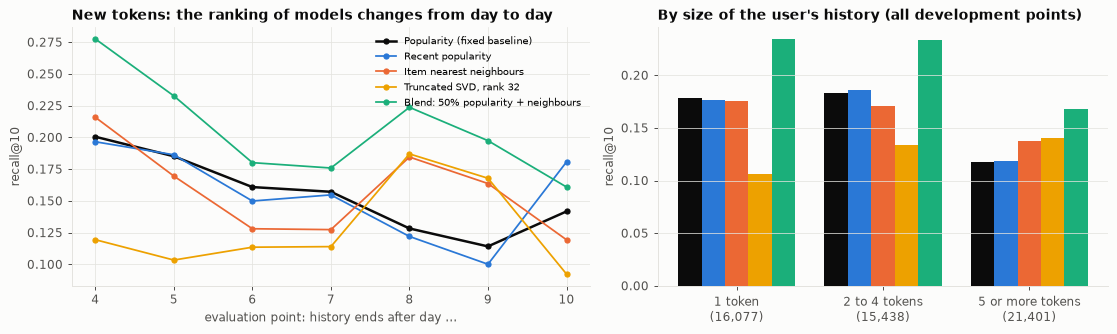

,1 token,2 to 4 tokens,5 or more tokens
Popularity (fixed baseline),0.179,0.183,0.117
Recent popularity,0.177,0.186,0.119
Item nearest neighbours,0.176,0.171,0.137
"Truncated SVD, rank 32",0.107,0.133,0.141
Blend: 50% popularity + neighbours,0.234,0.234,0.168
user evaluations,"16,077.000","15,438.000","21,401.000"


In [10]:
shown = ["Popularity (fixed baseline)", "Recent popularity", "Item nearest neighbours", "Truncated SVD, rank 32", "Blend: 50% popularity + neighbours"]
colors = [INK, BLUE, ORANGE, YELLOW, AQUA]
bounds = [(1, 1, "1 token"), (2, 4, "2 to 4 tokens"), (5, 10**9, "5 or more tokens")]
by_history = {}
for name in shown:
    frame = pd.concat(pooled[name])
    by_history[name] = {label: frame.loc[(frame["n_history"] >= low) & (frame["n_history"] <= high), "recall"].mean() for low, high, label in bounds}
by_history = pd.DataFrame(by_history).T
sizes = pd.concat(pooled[shown[0]])["n_history"]
by_history.loc["user evaluations"] = [int(((sizes >= low) & (sizes <= high)).sum()) for low, high, _ in bounds]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})
days = [day_of(o) for o in DEV_ORIGINS]
for name, color in zip(shown, colors):
    axes[0].plot(days, per_point.loc[name].to_numpy(), color=color, marker="o", markersize=4, label=name, linewidth=2 if "fixed" in name else 1.4)
axes[0].set_xlabel("evaluation point: history ends after day ..."); axes[0].set_ylabel("recall@10"); axes[0].set_xticks(days)
axes[0].set_title("New tokens: the ranking of models changes from day to day"); axes[0].legend(fontsize=8)

width = 0.16
for i, (name, color) in enumerate(zip(shown, colors)):
    axes[1].bar(np.arange(3) + (i - 2) * width, by_history.loc[name].astype(float), width=width, color=color)
axes[1].set_xticks(np.arange(3)); axes[1].set_xticklabels([f"{label}\n({int(n):,})" for label, n in by_history.loc["user evaluations"].items()])
axes[1].set_ylabel("recall@10"); axes[1].set_title("By size of the user's history (all development points)"); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); plt.show()
by_history

In [11]:
# Robustness: the same comparison under three changes, averaged over the development points.
def compare(make_setup, keep_users=None):
    rows = []
    for origin in DEV_ORIGINS:
        setup = make_setup(origin)
        task = setup["task"]
        if keep_users is not None:
            task = {**task, "eval_users": keep_users(task)}
        popularity, knn = pr.Popularity().fit(task["history"]), pr.ItemKNN(k=50, shrink=10).fit(task["history"])
        rows.append({"users per point": len(task["eval_users"]), "items": len(task["items"]),
                     "Popularity": pr.evaluate(popularity, task, K)["recall"].mean(),
                     "Item nearest neighbours": pr.evaluate(knn, task, K)["recall"].mean(),
                     "Blend: 50% popularity + neighbours": pr.evaluate(pr.Blend(popularity, knn, 0.5), task, K)["recall"].mean()})
    return pd.DataFrame(rows).mean()

def without_largest(task):
    sizes = np.asarray(task["history"].sum(axis=1)).ravel()[task["eval_users"]]
    return task["eval_users"][sizes <= np.quantile(sizes, 0.95)]

start = time.time()
variants = pd.DataFrame({
    "Tokens, buys and sells (main)": compare(lambda o: setups[o]),
    "Tokens, only first-time buys as target": compare(lambda o: make_task(o, future_side="buy")),
    "Tokens, without the 5% of users with the largest histories": compare(lambda o: setups[o], keep_users=without_largest),
    "Pools as items (the idea as first written)": compare(lambda o: make_task(o, frame=events, item="pool")),
}).T
print(f"mean recall@10 over the seven development points   ({time.time() - start:.0f}s)")
variants

mean recall@10 over the seven development points   (97s)


,users per point,items,Popularity,Item nearest neighbours,Blend: 50% popularity + neighbours
"Tokens, buys and sells (main)","7,559.429","12,914.000",0.155,0.158,0.207
"Tokens, only first-time buys as target","5,744.714","12,914.000",0.153,0.170,0.216
"Tokens, without the 5% of users with the largest histories","7,186.000","12,914.000",0.161,0.163,0.214
Pools as items (the idea as first written),"11,284.571","16,929.571",0.254,0.200,0.287


**Reading the results.**

- **Alone, collaborative filtering is no better than popularity.** Averaged over the development points,
  item nearest neighbours (0.158), popularity (0.155) and recent popularity (0.156) are level, and each
  wins on some days and loses on others. Truncated SVD is lower (0.128).
- **Combined with popularity, it helps, and consistently.** An equal blend of popularity and the
  nearest-neighbour score has the highest average recall (0.207, a third above the baseline) and beats the
  baseline at all seven development points. The two sources of information are complementary: popularity
  knows what many people trade, co-usage knows which of those fit this user.
- **The blend weight was not tuned carefully.** Two weights were tried with popularity; both beat the
  baseline at every point, and the equal blend is the better one.
- **The blend also recommends many more different tokens** than popularity, which never leaves the same
  handful.
- **History helps the collaborative models, as it should.** For users with a single token, nearest
  neighbours and SVD are level with popularity or below it. For users with five or more tokens both are
  ahead of it (0.14 against 0.12). The blend is ahead in every group. Users with large histories are the
  hardest to predict for every model; they are probably the most automated accounts.
- **Period effects dominate.** The ranking of the single models changes from day to day (left chart), and
  the whole level moves by a factor of almost two. Conclusions here need many evaluation points; seven
  overlapping ones are a start, not enough.
- **The picture holds under the variants tried:** with first-time buys only as the target and without the
  users with the largest histories. With pools as items all scores are higher, because that task includes
  the non-choices of section 3.1, and there nearest neighbours alone fall behind popularity.
- **15 to 25% of the problem is out of reach for all of these models:** tokens that did not exist in the
  history. They need information about the token itself.

## 6. Summary

| Question | Answer |
| --- | --- |
| Is the data usable? | Yes. Two weeks of swaps, complete and consistent, with the tokens of practically every pool. |
| Is there enough? | Events and users, yes. Evaluation periods, no: results swing widely from day to day, and two weeks give seven overlapping development points and one test point. |
| Features and labels? | The user-token matrix of the history. Labels: the tokens a user trades for the first time in the next two days. Exact and free. |
| Preprocessing? | Tokens instead of pools as items, pass-through tokens and base currencies removed, binary interactions, future-only tokens counted as misses. |
| Split? | One global timeline: ten days train, two dev, two test, with rolling evaluation points inside the first twelve days. |
| Baseline? | The most popular tokens of the history: recall@10 of about 0.16 on average, between 0.11 and 0.20 depending on the day. |
| Does collaborative filtering fit? | Alone it only matches popularity. Blended with popularity it is the best model at the development points. |

The full discussion is in [`research/pool_recommendation_writeup.md`](../../research/pool_recommendation_writeup.md).